### Letterboxing
Letterboxing ist eine Technik während des Pre-Processing um ein Bild/Frame auf eine quadratische Größe zu skalieren. YOLO akzeptiert nur quadratische Bilder. Üblicher weiße müssen diese in der Größe 640x640 eingelesen werden.

Falls ein Bild nicht quadratisch ist, muss dies entsprechend skaliert werden. Wichtig ist dabei, dass das Bild nicht gestreckt oder gestauscht wird, da sonst die Erkennung durch YOLO beeinträchtigt wird. Beim Letterboxing wird die größere Seite als Referenz genommen und der restliche Bereich mit einer Farbe ausgefüllt.


Image shape: (3762, 2649, 3)
Resized image shape: (640, 450, 3)
Canvas shape: (640, 640, 3)


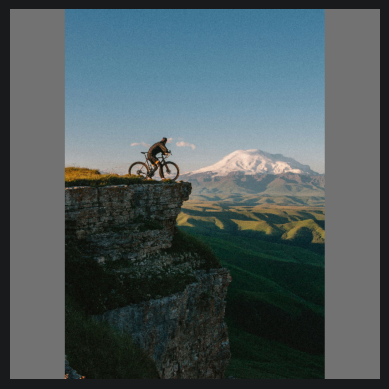

In [12]:
import matplotlib.pyplot as plt

import numpy as np
import cv2 as cv

req_size = 640
image: np.ndarray = cv.imread('pictures/bicycle.jpg')

# The image has the format HWC, take the height and width of it.
height, width = image.shape[:2]
print(f"Image shape: {image.shape}")

# Take the scale ratio from the longest side
scale = min(req_size / height, req_size / width)
new_height, new_width = int(height * scale), int(width * scale)

# Resize the image
resized_image = cv.resize(image, (new_width, new_height))
print(f"Resized image shape: {resized_image.shape}")

# Create the canvas / final image
canvas_shape = (req_size, req_size, 3)
canvas_color = (114, 114, 114)
canvas = np.full(shape=canvas_shape, fill_value=canvas_color, dtype=np.uint8)

# Fill the corners
vertical = (req_size - new_height) // 2
horizontal = (req_size - new_width) // 2

# Fill the canvas with the resized image
canvas[vertical:new_height + vertical, horizontal:new_width + horizontal] = resized_image
print(f"Canvas shape: {canvas.shape}")


# Transform BGR to RGB for matplotlib
canvas_rgb = cv.cvtColor(canvas, cv.COLOR_BGR2RGB)
plt.imshow(canvas_rgb)
plt.axis("off")
plt.show()